# 01 — Tonsil1 Leiden vs cell type

Unimodal Leiden resolution sweep on preprocessed Tonsil1 embeddings for the
RNA ∩ H3K27ac ∩ H3K27me3 overlap (**2,831** cells). Main-paper **Figure 2**.

- RNA: `X_pca`; chromatin: `X_spectral_harmony` (unchanged)
- Neighbor graphs recomputed on the overlap
- Leiden resolutions **0.25–3.0** (step 0.25)
- Labels: `CellType`
- Metrics: n clusters, ARI, NMI, H(cell type|clusters), H(clusters|cell type), homogeneity

**Figure panels below are drawn from the frozen table** bundled as
`paper_results/tonsil1_celltype_leiden_resolution.csv`, which matches the manuscript
curves. Neighbor-graph construction and Leiden clustering are intrinsically
stochastic: even with a fixed random seed, a full recompute can change cluster
counts and agreement metrics slightly. That is expected and does not indicate
an error in the analysis. An optional regenerate snippet is included at the end
(commented out) for transparency.

Plots are shown inline only (file writes commented out).


In [7]:
%matplotlib inline
import sys
import warnings
from pathlib import Path

warnings.simplefilter("ignore", FutureWarning)
warnings.simplefilter("ignore", UserWarning)

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PACKAGE = Path("/mnt/data1/divyanshu/treseq/tonsils/codes/treseq_paper")
if str(PACKAGE.parent) not in sys.path:
    sys.path.insert(0, str(PACKAGE.parent))

from treseq_paper import config
import importlib
importlib.reload(config)
from treseq_paper.load_resolution import plot_resolution_sweep

sns.set_theme("talk", style="ticks")
plt.rcParams["figure.dpi"] = 120

TABLE = config.TONSIL1_LEIDEN_VS_CELLTYPE_CSV
if not TABLE.is_file():
    raise FileNotFoundError(TABLE)


## Frozen table (matches the manuscript figure)


In [8]:
vs = pd.read_csv(TABLE)
leiden = vs.query("algorithm == 'leiden'").copy()
if set(leiden["modality"]) != set(config.MODALITIES):
    raise RuntimeError(f"unexpected modalities: {sorted(leiden['modality'].unique())}")
print(f"loaded {TABLE.name}: {len(leiden)} Leiden rows")
display(leiden.round(4))


loaded tonsil1_celltype_leiden_resolution.csv: 36 Leiden rows


,algorithm,modality,clustering,param,n_clusters,n_types,ARI,NMI,AMI,H_celltype_given_clusters,H_clusters_given_celltype,homogeneity_clusters_given_celltype,completeness_clusters_given_celltype
0,leiden,RNA,RNA,0.25,6,15,0.4592,0.7115,0.7095,1.4786,0.0828,0.5657,0.9588
1,leiden,H3K27ac,H3K27ac,0.25,4,15,0.3439,0.5040,0.5018,2.1221,0.4018,0.3767,0.7614
2,leiden,H3K27me3,H3K27me3,0.25,4,15,0.3358,0.4884,0.4862,2.1556,0.4604,0.3668,0.7306
3,leiden,RNA,RNA,0.50,9,15,0.5103,0.7374,0.7348,1.2554,0.2750,0.6312,0.8865
4,leiden,H3K27ac,H3K27ac,0.50,5,15,0.3177,0.4825,0.4797,2.0875,0.7370,0.3868,0.6412
5,leiden,H3K27me3,H3K27me3,0.50,6,15,0.2906,0.4573,0.4538,2.0757,1.0778,0.3903,0.5521
6,leiden,RNA,RNA,0.75,13,15,0.5516,0.7273,0.7236,0.9851,0.8294,0.7106,0.7447
7,leiden,H3K27ac,H3K27ac,0.75,7,15,0.3173,0.4515,0.4473,2.0685,1.1772,0.3924,0.5315
8,leiden,H3K27me3,H3K27me3,0.75,10,15,0.2546,0.4279,0.4219,2.0060,1.7335,0.4107,0.4465
9,leiden,RNA,RNA,1.00,13,15,0.5630,0.7313,0.7277,0.9475,0.8581,0.7217,0.7412


## Resolution-sweep figure


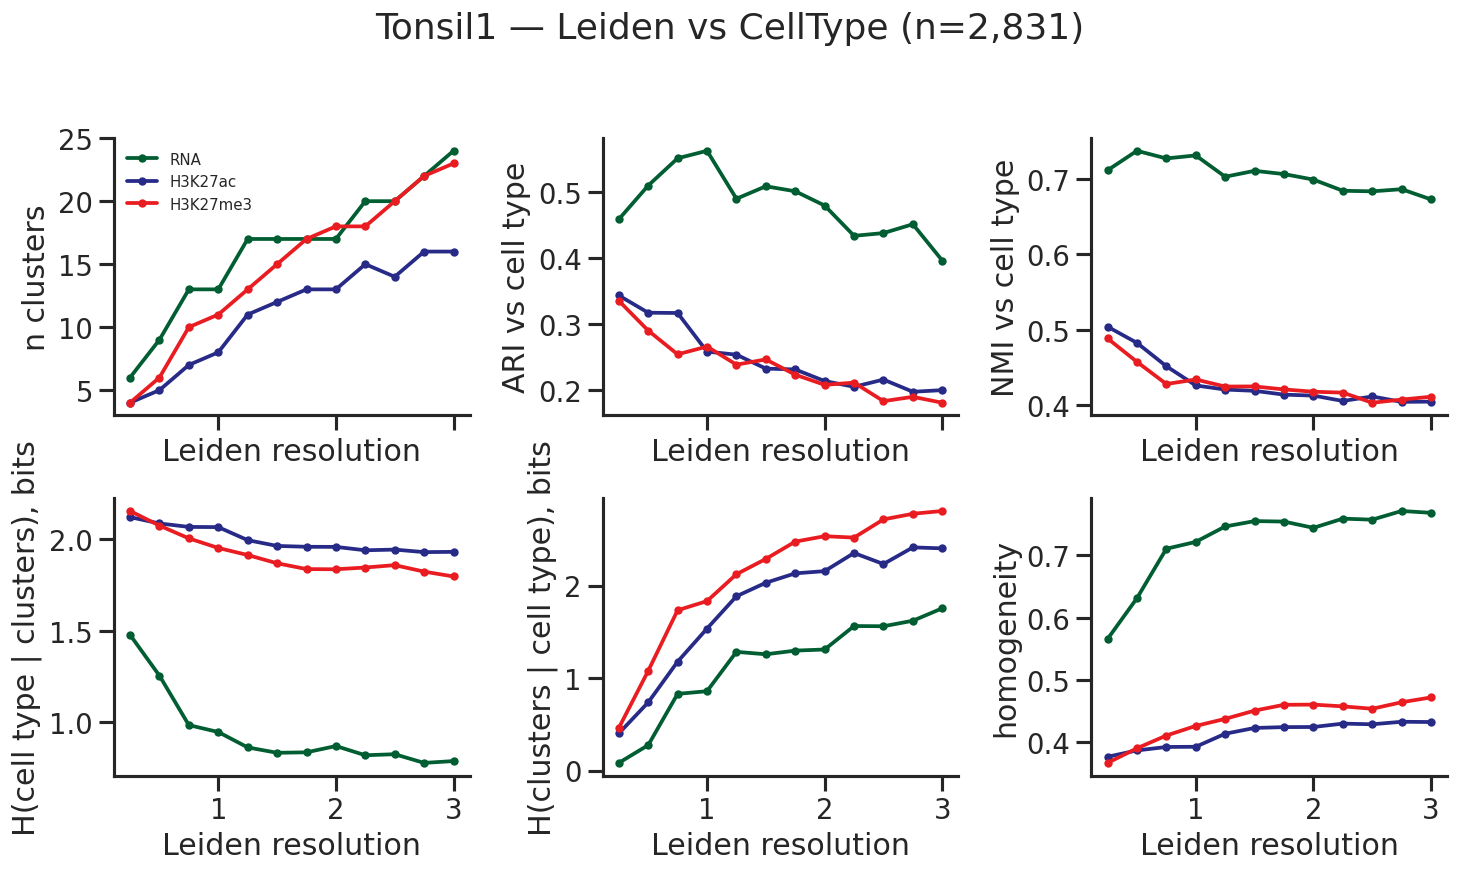

In [9]:
fig, axes = plot_resolution_sweep(
    vs,
    title="Tonsil1 — Leiden vs CellType (n=2,831)",
)
plt.show()
# fig.savefig("tonsil1_celltype_leiden_resolution.pdf", bbox_inches="tight")  # disabled


## Optional: regenerate the table (commented out)

Uncomment the cell below only if you want to recompute Leiden from the
preprocessed objects. Results will be close to the frozen table but are **not
guaranteed to match it bit-for-bit**: nearest-neighbor graphs and Leiden
partitions retain mild run-to-run variability even with `random_state=42`.
Use the frozen table above for manuscript-identical curves.


In [10]:
# from treseq_paper.load_resolution import banner, leiden_vs_celltype, load_tonsil1
#
# bundle = load_tonsil1()
# banner(bundle)
# display(pd.Series(bundle["celltype_counts"], name="n_cells").sort_values(ascending=False).to_frame())
#
# print("Leiden vs CellType (recompute; may differ mildly from the frozen table) …", flush=True)
# vs_recomputed, labels_by_res = leiden_vs_celltype(bundle)
# display(vs_recomputed.round(4))
#
# fig, axes = plot_resolution_sweep(
#     vs_recomputed,
#     title="Tonsil1 — Leiden vs CellType (recomputed)",
# )
# plt.show()
